In [6]:
import pickle as pkl
import pandas as pd
import numpy as np
import plotly as plt
from pico.service import Utils
from override_Controller import Controller

In [1]:
file_ml_pico = "test_data/pico_ml_20261015_182334_paired_1ksplits.mtxp"

In [8]:
controller = Controller()
dto = Utils.load_metabo_expe(file_ml_pico)
controller.full_restore(dto)

In [46]:
# df = self.r[design_name][algo].results["accuracies_table"]
r = controller.get_all_results()
expe_design = list(r.keys())[0]
expe_design

'0_convalescence_vs_1_acute'

In [13]:
df = r[expe_design]["DecisionTree"].results["accuracies_table"]

In [14]:
df

,splits,balanced accuracies,color
0,0,0.864130,train
1,0,0.729167,test
2,1,0.907726,train
3,1,0.750000,test
4,2,0.967742,train
...,...,...,...
1995,997,0.666667,test
1996,998,0.853904,train
1997,998,0.916667,test
1998,999,0.940510,train


In [15]:
import plotly.express as px

# One row per split, with train and test as columns
wide = df.pivot(index="splits", columns="color", values="balanced accuracies").sort_index()
wide

color,test,train
splits,,
0,0.729167,0.864130
1,0.750000,0.907726
10,0.666667,0.989189
100,0.895833,0.951554
101,0.812500,0.951496
...,...,...
995,0.770833,0.978319
996,0.870471,0.983871
997,0.666667,0.973001


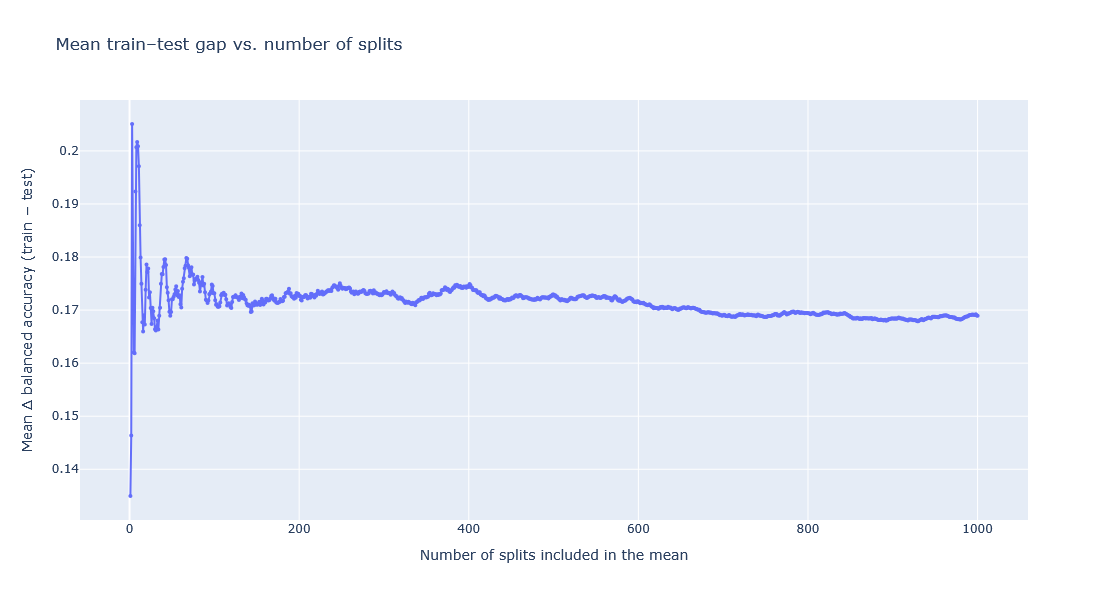

In [20]:
# Splits are added in index order (0, 1, 2, …). 
# If you'd rather avoid any ordering effect, shuffle them first with wide = wide.sample(frac=1, random_state=0) before computing n_splits.

# Delta for each split, then the running mean over the first n splits
wide["delta"] = wide["train"] - wide["test"]
wide["n_splits"] = range(1, len(wide) + 1)
wide["mean_delta"] = wide["delta"].expanding().mean()

fig = px.scatter(
    wide,
    x="n_splits",
    y="mean_delta",
    labels={
        "n_splits": "Number of splits included in the mean",
        "mean_delta": "Mean Δ balanced accuracy (train − test)",
    },
    title="Mean train–test gap vs. number of splits",
)
fig.update_traces(mode="lines+markers", marker=dict(size=4))
fig.update_layout(height=600)

fig.show()

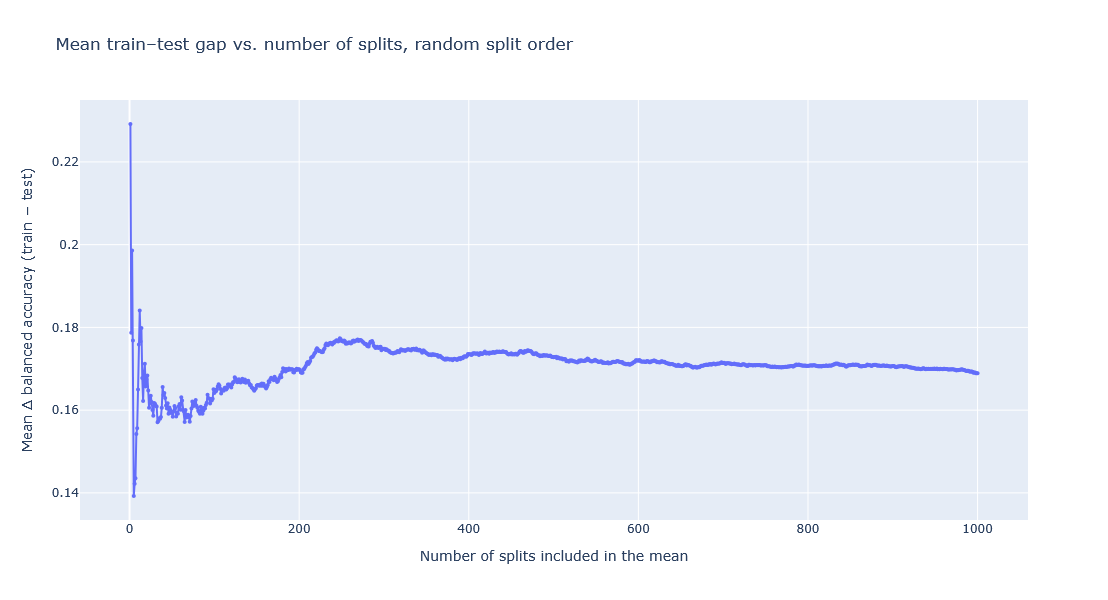

In [21]:
# Splits are added in index order (0, 1, 2, …). 
# If you'd rather avoid any ordering effect, shuffle them first with wide = wide.sample(frac=1, random_state=0) before computing n_splits.

# Delta for each split, then the running mean over the first n splits
wide["delta"] = wide["train"] - wide["test"]
wide = wide.sample(frac=1, random_state=0)
wide["n_splits"] = range(1, len(wide) + 1)
wide["mean_delta"] = wide["delta"].expanding().mean()

fig = px.scatter(
    wide,
    x="n_splits",
    y="mean_delta",
    labels={
        "n_splits": "Number of splits included in the mean",
        "mean_delta": "Mean Δ balanced accuracy (train − test)",
    },
    title="Mean train–test gap vs. number of splits, random split order",
)
fig.update_traces(mode="lines+markers", marker=dict(size=4))
fig.update_layout(height=600)

fig.show()

In [27]:
l_f = r[expe_design]["DecisionTree"].results['0']["feature_importances"]

In [28]:
l_l_features = []
for s in range(0, 1000):
    l_l_features.append(r[expe_design]["DecisionTree"].results[str(s)]["feature_importances"])

In [34]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import spearmanr

# l_l_features: list of 1000 splits, each a list of (feature_name, importance) tuples
imp = pd.DataFrame([dict(split) for split in l_l_features]).fillna(0.0)   # (n_splits, n_features)
N = len(imp)
n = np.arange(1, N + 1)

final_mean = imp.mean().sort_values(ascending=False)
TOP_K = 20
top = list(final_mean.index[:TOP_K])
rng = np.random.default_rng(0)

PALETTE = px.colors.qualitative.Plotly
TEMPLATE = "simple_white"

def rgba(hex_color, a):
    h = hex_color.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{a})"

def add_band(fig, x, lo, hi, color, group=None, row=None, col=None):
    """Shaded band between lo and hi (upper trace, then lower trace filled to it)."""
    kw = dict(row=row, col=col) if row is not None else {}
    fig.add_trace(go.Scatter(x=x, y=hi, mode="lines", line=dict(width=0),
                             legendgroup=group, showlegend=False, hoverinfo="skip"), **kw)
    fig.add_trace(go.Scatter(x=x, y=lo, mode="lines", line=dict(width=0),
                             fill="tonexty", fillcolor=rgba(color, 0.18),
                             legendgroup=group, showlegend=False, hoverinfo="skip"), **kw)


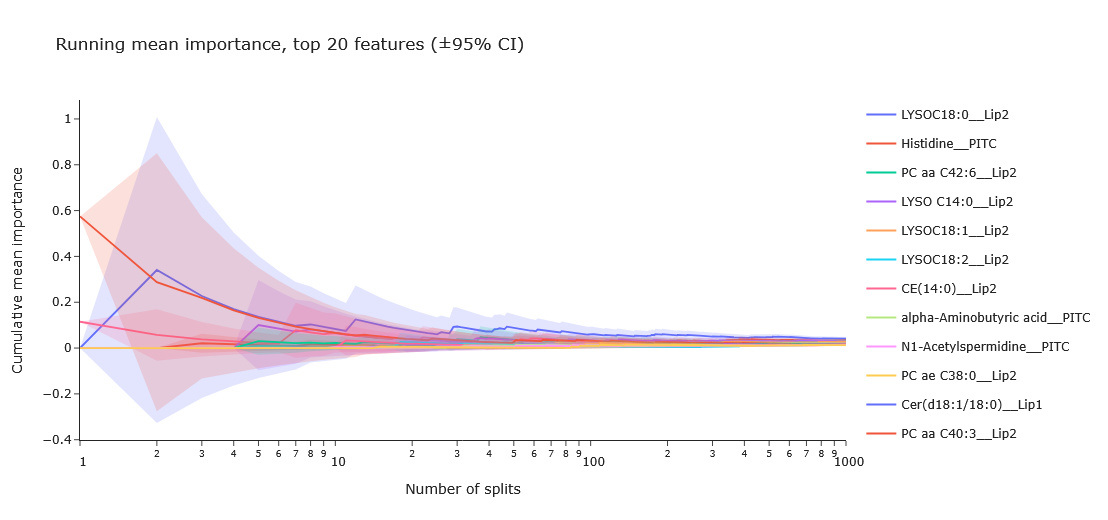

In [35]:
cum_mean = imp.cumsum().div(n, axis=0)
cum_sq   = (imp ** 2).cumsum().div(n, axis=0)
var      = (cum_sq - cum_mean ** 2).mul(n / np.maximum(n - 1, 1), axis=0).clip(lower=0)
sem      = np.sqrt(var).div(np.sqrt(n), axis=0)

fig1 = go.Figure()
for i, f in enumerate(top):
    c = PALETTE[i % len(PALETTE)]
    add_band(fig1, n, cum_mean[f] - 1.96 * sem[f], cum_mean[f] + 1.96 * sem[f], c, group=f)
    fig1.add_trace(go.Scatter(x=n, y=cum_mean[f], mode="lines", name=f, legendgroup=f,
                              line=dict(color=c, width=1.8),
                              hovertemplate=f"<b>{f}</b><br>splits=%{{x}}<br>mean=%{{y:.4f}}<extra></extra>"))
fig1.update_layout(template=TEMPLATE, width=950, height=520,
                   title=f"Running mean importance, top {TOP_K} features (±95% CI)",
                   xaxis=dict(type="log", title="Number of splits"),
                   yaxis_title="Cumulative mean importance", hovermode="x unified")
fig1.show()


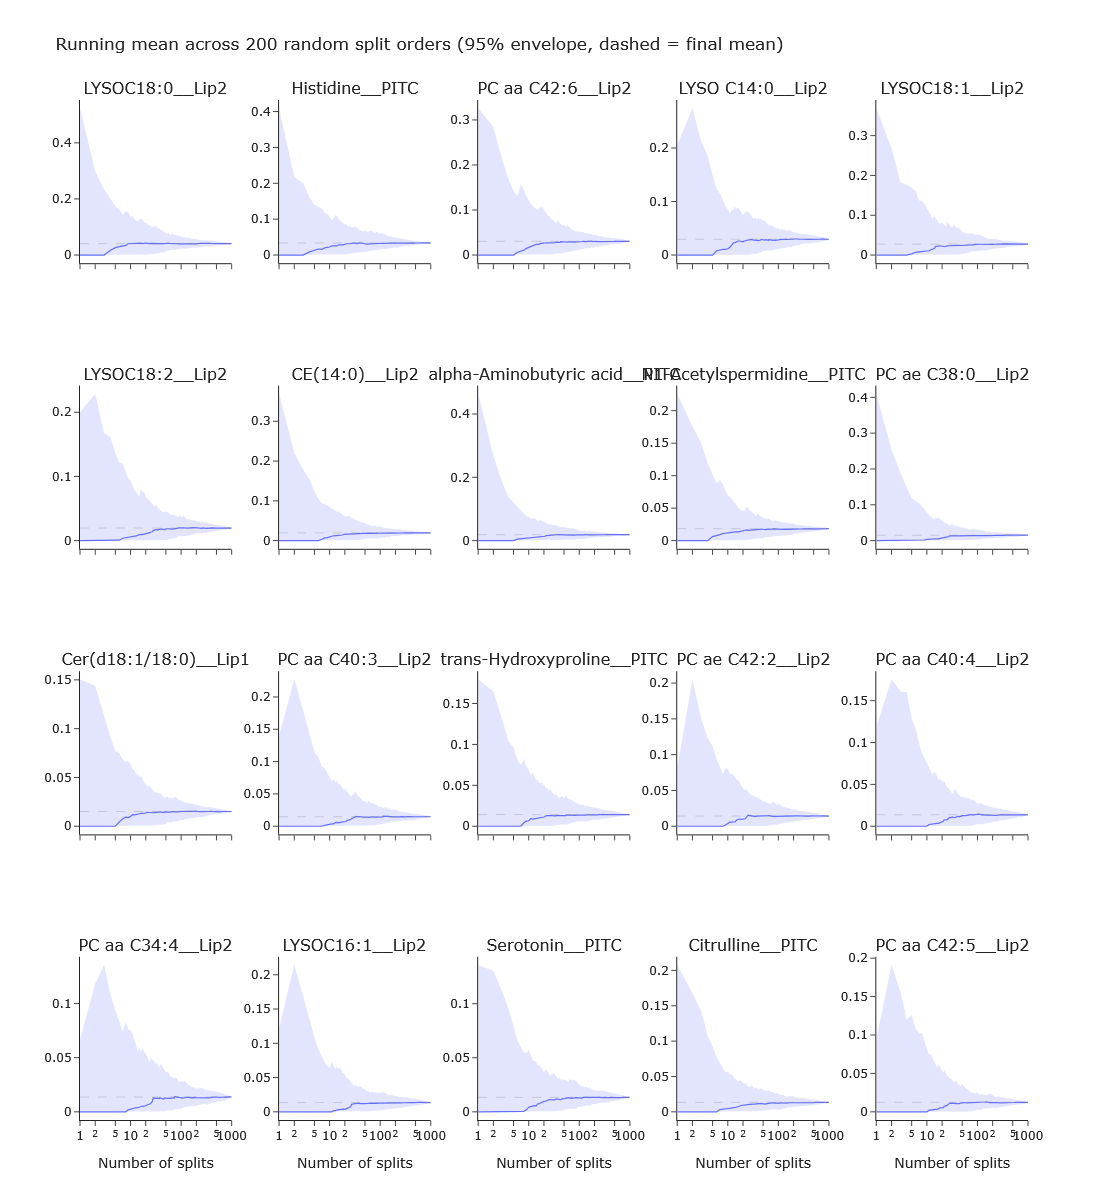

In [36]:
B = 200
X = imp[top].to_numpy()                                    # (N, K)
perm_idx = np.array([rng.permutation(N) for _ in range(B)])
runs = X[perm_idx].cumsum(axis=1) / n[None, :, None]      # (B, N, K)
lo, med, hi = np.percentile(runs, [2.5, 50, 97.5], axis=0)

ncols = 5
nrows = int(np.ceil(TOP_K / ncols))
fig2 = make_subplots(rows=nrows, cols=ncols, subplot_titles=top,
                     shared_xaxes=True, horizontal_spacing=0.05, vertical_spacing=0.12)
for k, f in enumerate(top):
    r, c = k // ncols + 1, k % ncols + 1
    color = PALETTE[0]
    add_band(fig2, n, lo[:, k], hi[:, k], color, row=r, col=c)
    fig2.add_trace(go.Scatter(x=n, y=med[:, k], mode="lines", line=dict(color=color, width=1.2),
                              showlegend=False, name=f), row=r, col=c)
    fig2.add_hline(y=final_mean[f], line=dict(color="gray", dash="dash", width=1), row=r, col=c)
fig2.update_xaxes(type="log")
fig2.update_xaxes(title_text="Number of splits", row=nrows)
fig2.update_layout(template=TEMPLATE, width=1300, height=300 * nrows,
                   title="Running mean across 200 random split orders (95% envelope, dashed = final mean)")
fig2.show()


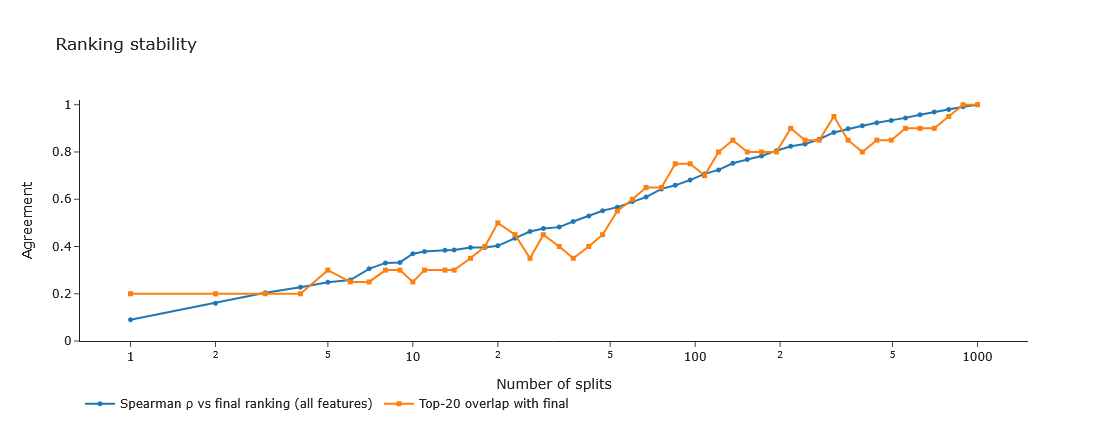

In [37]:
checkpoints = np.unique(np.logspace(0, np.log10(N), 60).astype(int))
final_top = set(top)
rho, overlap = [], []
for cp in checkpoints:
    m = cum_mean.iloc[cp - 1]
    rho.append(spearmanr(m, final_mean.reindex(m.index)).statistic)
    overlap.append(len(set(m.nlargest(TOP_K).index) & final_top) / TOP_K)

fig3 = go.Figure()
fig3.add_trace(go.Scatter(x=checkpoints, y=rho, mode="lines+markers", marker_size=5,
                          name="Spearman ρ vs final ranking (all features)"))
fig3.add_trace(go.Scatter(x=checkpoints, y=overlap, mode="lines+markers", marker_size=5,
                          marker_symbol="square", name=f"Top-{TOP_K} overlap with final"))
fig3.update_layout(template=TEMPLATE, width=850, height=430,
                   title="Ranking stability",
                   xaxis=dict(type="log", title="Number of splits"),
                   yaxis=dict(range=[0, 1.02], title="Agreement"),
                   legend=dict(orientation="h", y=-0.2))
fig3.show()


# Random Forest

In [53]:
# l_f = r[expe_design]['RandomForest'].results['0']["feature_importances"]
# l_f

In [52]:
l_l_features = []
for s in range(0, 1000):
    l_l_features.append(r[expe_design]["RandomForest"].results[str(s)]["feature_importances"])

In [54]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import spearmanr

# l_l_features: list of 1000 splits, each a list of (feature_name, importance) tuples
imp = pd.DataFrame([dict(split) for split in l_l_features]).fillna(0.0)   # (n_splits, n_features)
N = len(imp)
n = np.arange(1, N + 1)

final_mean = imp.mean().sort_values(ascending=False)
TOP_K = 20
top = list(final_mean.index[:TOP_K])
rng = np.random.default_rng(0)

PALETTE = px.colors.qualitative.Plotly
TEMPLATE = "simple_white"

def rgba(hex_color, a):
    h = hex_color.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return f"rgba({r},{g},{b},{a})"

def add_band(fig, x, lo, hi, color, group=None, row=None, col=None):
    """Shaded band between lo and hi (upper trace, then lower trace filled to it)."""
    kw = dict(row=row, col=col) if row is not None else {}
    fig.add_trace(go.Scatter(x=x, y=hi, mode="lines", line=dict(width=0),
                             legendgroup=group, showlegend=False, hoverinfo="skip"), **kw)
    fig.add_trace(go.Scatter(x=x, y=lo, mode="lines", line=dict(width=0),
                             fill="tonexty", fillcolor=rgba(color, 0.18),
                             legendgroup=group, showlegend=False, hoverinfo="skip"), **kw)


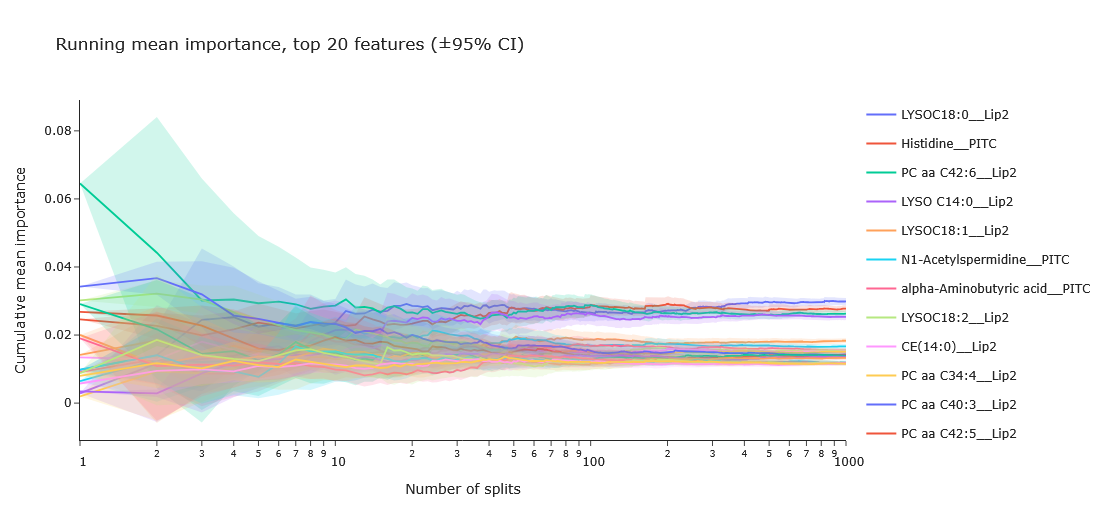

In [55]:
cum_mean = imp.cumsum().div(n, axis=0)
cum_sq   = (imp ** 2).cumsum().div(n, axis=0)
var      = (cum_sq - cum_mean ** 2).mul(n / np.maximum(n - 1, 1), axis=0).clip(lower=0)
sem      = np.sqrt(var).div(np.sqrt(n), axis=0)

fig1 = go.Figure()
for i, f in enumerate(top):
    c = PALETTE[i % len(PALETTE)]
    add_band(fig1, n, cum_mean[f] - 1.96 * sem[f], cum_mean[f] + 1.96 * sem[f], c, group=f)
    fig1.add_trace(go.Scatter(x=n, y=cum_mean[f], mode="lines", name=f, legendgroup=f,
                              line=dict(color=c, width=1.8),
                              hovertemplate=f"<b>{f}</b><br>splits=%{{x}}<br>mean=%{{y:.4f}}<extra></extra>"))
fig1.update_layout(template=TEMPLATE, width=950, height=520,
                   title=f"Running mean importance, top {TOP_K} features (±95% CI)",
                   xaxis=dict(type="log", title="Number of splits"),
                   yaxis_title="Cumulative mean importance", hovermode="x unified")
fig1.show()


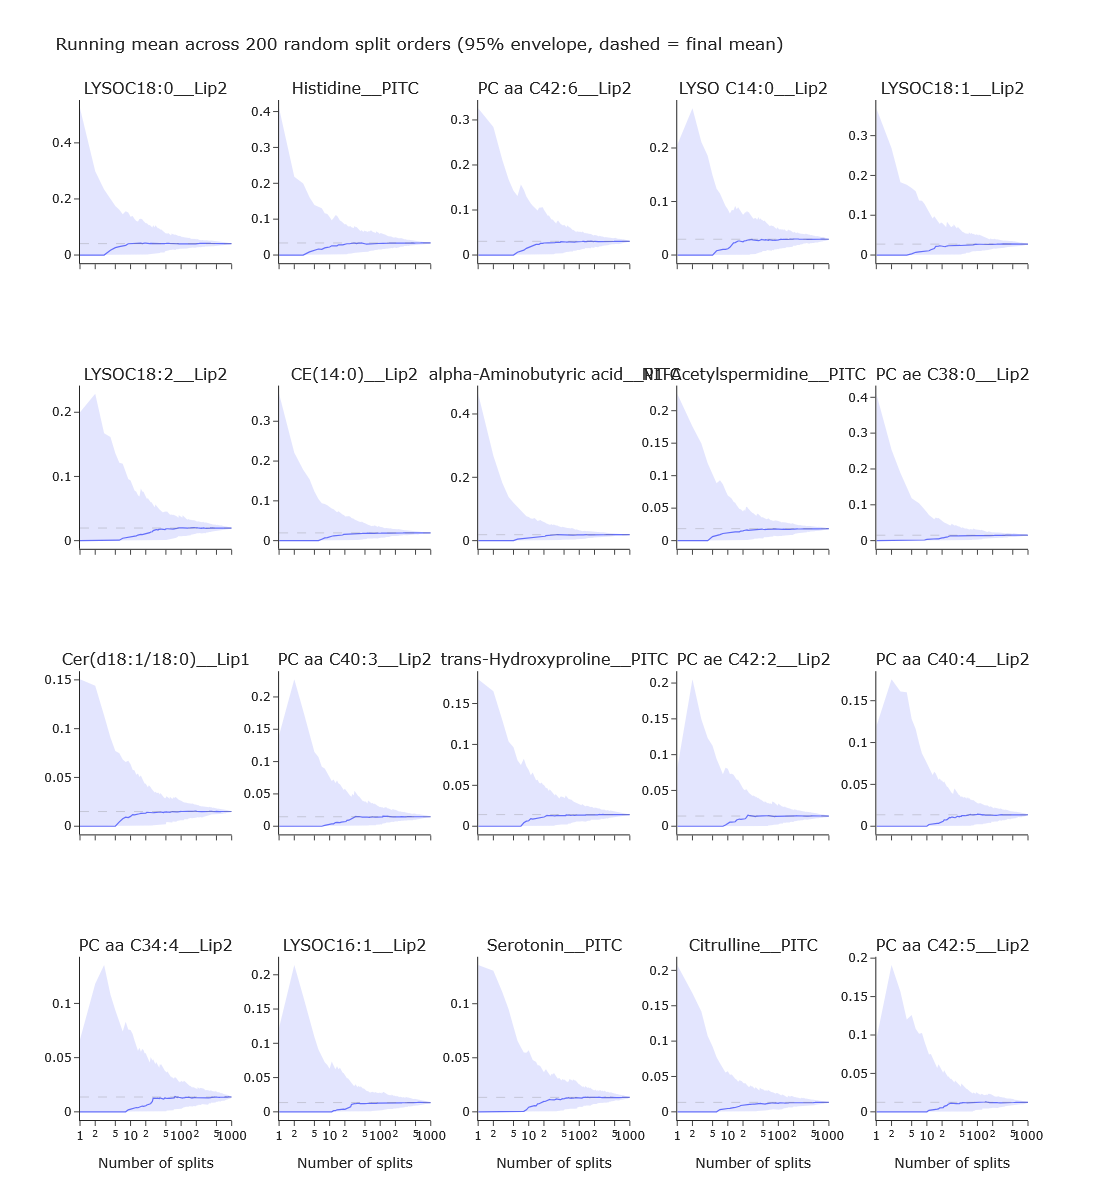

In [36]:
B = 200
X = imp[top].to_numpy()                                    # (N, K)
perm_idx = np.array([rng.permutation(N) for _ in range(B)])
runs = X[perm_idx].cumsum(axis=1) / n[None, :, None]      # (B, N, K)
lo, med, hi = np.percentile(runs, [2.5, 50, 97.5], axis=0)

ncols = 5
nrows = int(np.ceil(TOP_K / ncols))
fig2 = make_subplots(rows=nrows, cols=ncols, subplot_titles=top,
                     shared_xaxes=True, horizontal_spacing=0.05, vertical_spacing=0.12)
for k, f in enumerate(top):
    r, c = k // ncols + 1, k % ncols + 1
    color = PALETTE[0]
    add_band(fig2, n, lo[:, k], hi[:, k], color, row=r, col=c)
    fig2.add_trace(go.Scatter(x=n, y=med[:, k], mode="lines", line=dict(color=color, width=1.2),
                              showlegend=False, name=f), row=r, col=c)
    fig2.add_hline(y=final_mean[f], line=dict(color="gray", dash="dash", width=1), row=r, col=c)
fig2.update_xaxes(type="log")
fig2.update_xaxes(title_text="Number of splits", row=nrows)
fig2.update_layout(template=TEMPLATE, width=1300, height=300 * nrows,
                   title="Running mean across 200 random split orders (95% envelope, dashed = final mean)")
fig2.show()


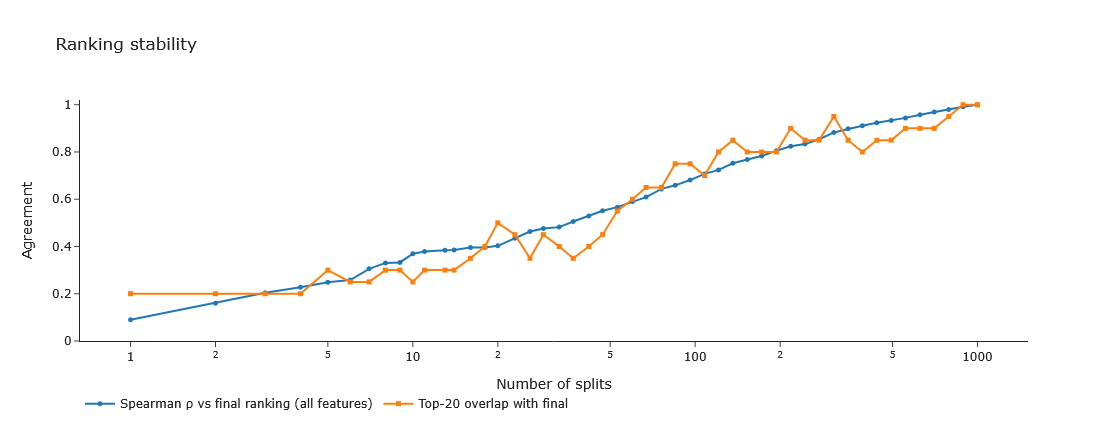

In [37]:
checkpoints = np.unique(np.logspace(0, np.log10(N), 60).astype(int))
final_top = set(top)
rho, overlap = [], []
for cp in checkpoints:
    m = cum_mean.iloc[cp - 1]
    rho.append(spearmanr(m, final_mean.reindex(m.index)).statistic)
    overlap.append(len(set(m.nlargest(TOP_K).index) & final_top) / TOP_K)

fig3 = go.Figure()
fig3.add_trace(go.Scatter(x=checkpoints, y=rho, mode="lines+markers", marker_size=5,
                          name="Spearman ρ vs final ranking (all features)"))
fig3.add_trace(go.Scatter(x=checkpoints, y=overlap, mode="lines+markers", marker_size=5,
                          marker_symbol="square", name=f"Top-{TOP_K} overlap with final"))
fig3.update_layout(template=TEMPLATE, width=850, height=430,
                   title="Ranking stability",
                   xaxis=dict(type="log", title="Number of splits"),
                   yaxis=dict(range=[0, 1.02], title="Agreement"),
                   legend=dict(orientation="h", y=-0.2))
fig3.show()
